# Pair 1: BrushNet vs PowerPaint

I compared the two models on the same 100 ABO product images with three masks for each image. I compare reconstruction quality, consistency and inference time using the same test cases.

## 1. Load results

I use the metrics saved by the two model notebooks. Each row is one image and mask.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Find the Pair 1 folder
pair = Path.cwd()
if not (pair / "results").exists():
    pair = pair / "Models/Pair_01"

results = pair / "results"
brush = pd.read_csv(results / "BrushNet/metrics.csv")
power = pd.read_csv(results / "PowerPaint/metrics.csv")

# Keep completed cases and match their case IDs
if "status" in brush.columns:
    brush = brush[brush["status"] == "ok"]
if "status" in power.columns:
    power = power[power["status"] == "ok"]

both = brush.merge(power, on="case_id", suffixes=("_brush", "_power"))
print("Cases compared:", len(both))

Cases compared: 300


## 2. Overall results

Higher PSNR and SSIM are better. Lower LPIPS and time are better. I also compare average inference time using a simple bar chart.

In [2]:
metrics = ["masked_psnr", "masked_ssim", "masked_lpips", "unmasked_ssim", "time_seconds"]

# Compare the average score for each model
summary = pd.DataFrame({
    "BrushNet": [both[f"{m}_brush"].mean() for m in metrics],
    "PowerPaint": [both[f"{m}_power"].mean() for m in metrics]
}, index=metrics)

display(summary.round(3))
summary.to_csv(results / "comparison_summary.csv")

,BrushNet,PowerPaint
masked_psnr,10.558,8.480
masked_ssim,0.322,0.230
masked_lpips,0.637,0.730
unmasked_ssim,0.935,0.925
time_seconds,4.999,5.986


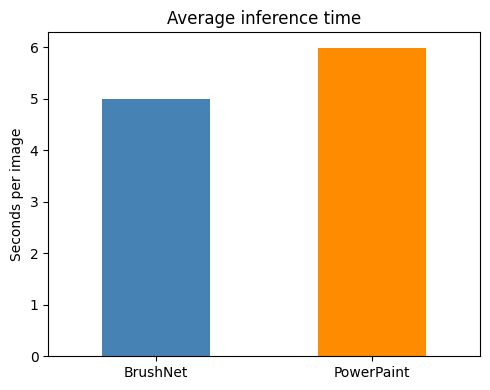

In [3]:
# Compare average inference time
fig, ax = plt.subplots(figsize=(5, 4))
summary.loc["time_seconds"].plot(kind="bar", ax=ax, color=["steelblue", "darkorange"])
ax.set_title("Average inference time")
ax.set_ylabel("Seconds per image")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.savefig(results / "inference_time.png", dpi=150)
plt.show()

## 3. Results by mask size

I checked small, medium and large masks and plotted the average reconstruction scores for each size.

,mask_type,model,masked_psnr,masked_ssim,masked_lpips,unmasked_ssim,time_seconds
0,small,BrushNet,12.919,0.409,0.503,0.932,5.027
1,small,PowerPaint,8.527,0.234,0.697,0.919,5.995
2,medium,BrushNet,9.882,0.298,0.673,0.934,4.984
3,medium,PowerPaint,8.503,0.224,0.737,0.925,5.986
4,large,BrushNet,8.873,0.260,0.735,0.940,4.986
5,large,PowerPaint,8.409,0.232,0.756,0.932,5.977


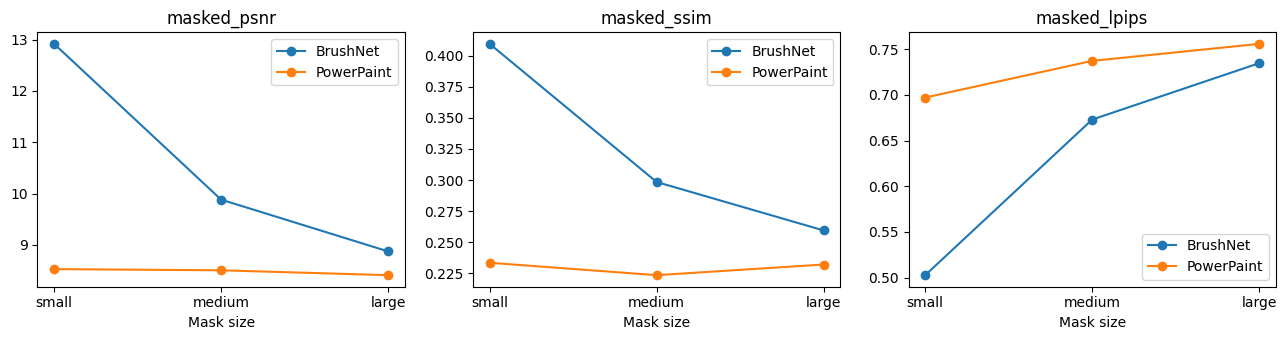

In [4]:
# Compare the two models for each mask size
mask_results = []
for mask in ["small", "medium", "large"]:
    group = both[both["mask_type_brush"] == mask]
    for model, suffix in [("BrushNet", "brush"), ("PowerPaint", "power")]:
        row = {"mask_type": mask, "model": model}
        row.update({m: group[f"{m}_{suffix}"].mean() for m in metrics})
        mask_results.append(row)

by_mask = pd.DataFrame(mask_results)
display(by_mask.round(3))
by_mask.to_csv(results / "comparison_by_mask.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, metric in zip(axes, ["masked_psnr", "masked_ssim", "masked_lpips"]):
    for model in ["BrushNet", "PowerPaint"]:
        data = by_mask[by_mask["model"] == model]
        ax.plot(data["mask_type"], data[metric], marker="o", label=model)
    ax.set_title(metric)
    ax.set_xlabel("Mask size")
    ax.legend()
plt.tight_layout()
plt.savefig(results / "metrics_by_mask.png", dpi=150)
plt.show()

The boxplot shows the spread of masked SSIM scores, including weaker results that are hidden by the average.

C:\Users\royay\AppData\Local\Temp\ipykernel_25568\1287465505.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


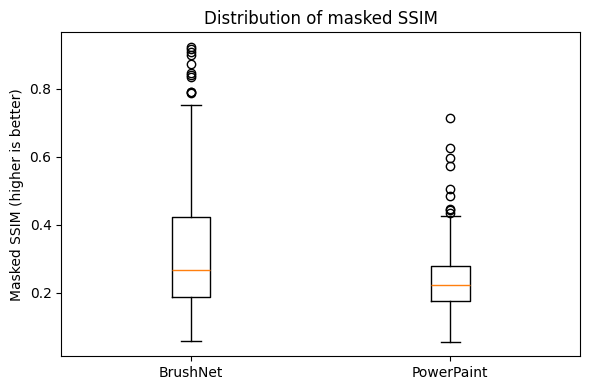

In [5]:
# Show how much the SSIM scores vary between images
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(
    [both["masked_ssim_brush"].dropna(), both["masked_ssim_power"].dropna()],
    labels=["BrushNet", "PowerPaint"]
)
ax.set_title("Distribution of masked SSIM")
ax.set_ylabel("Masked SSIM (higher is better)")
plt.tight_layout()
plt.savefig(results / "ssim_boxplot.png", dpi=150)
plt.show()

## 4. Visual comparison

I looked at a few cases where the models gave different SSIM scores and some randomly selected examples. This helps show mistakes that cannot be explained by the numbers alone.

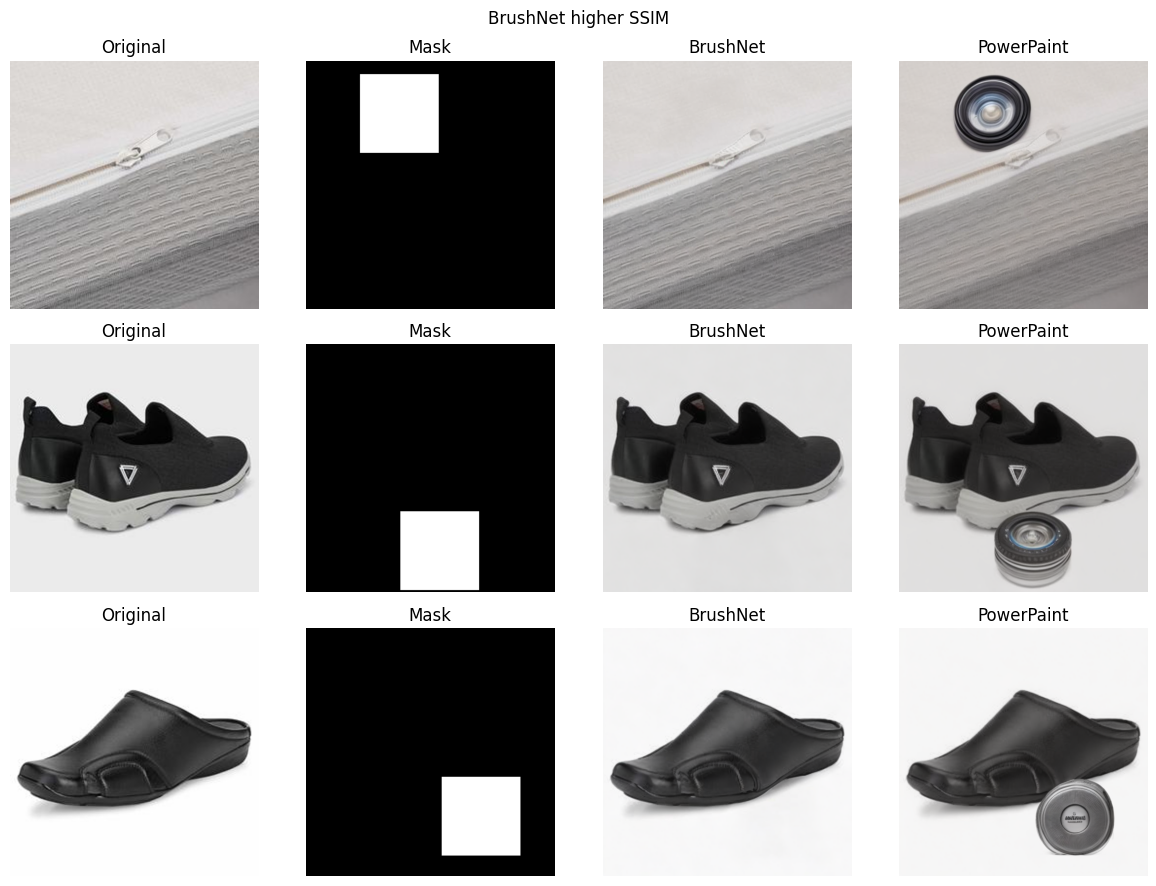

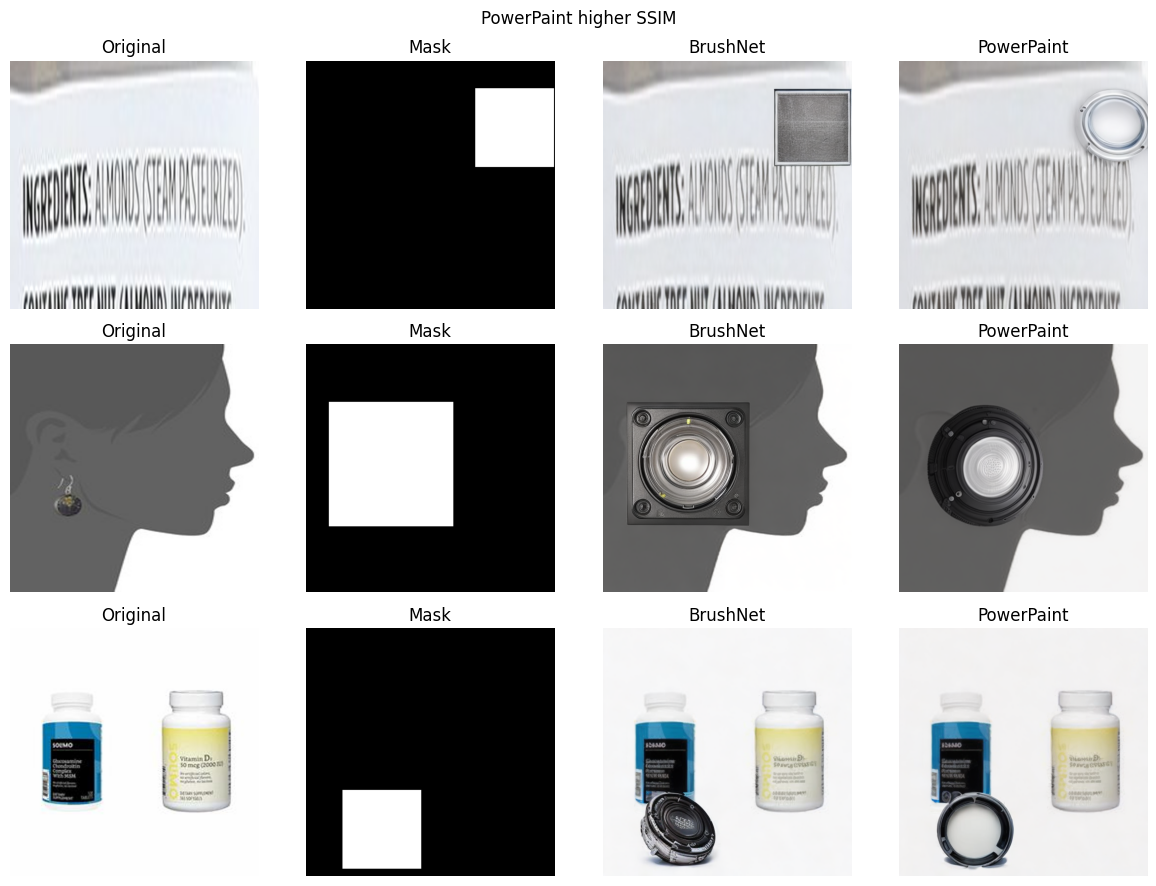

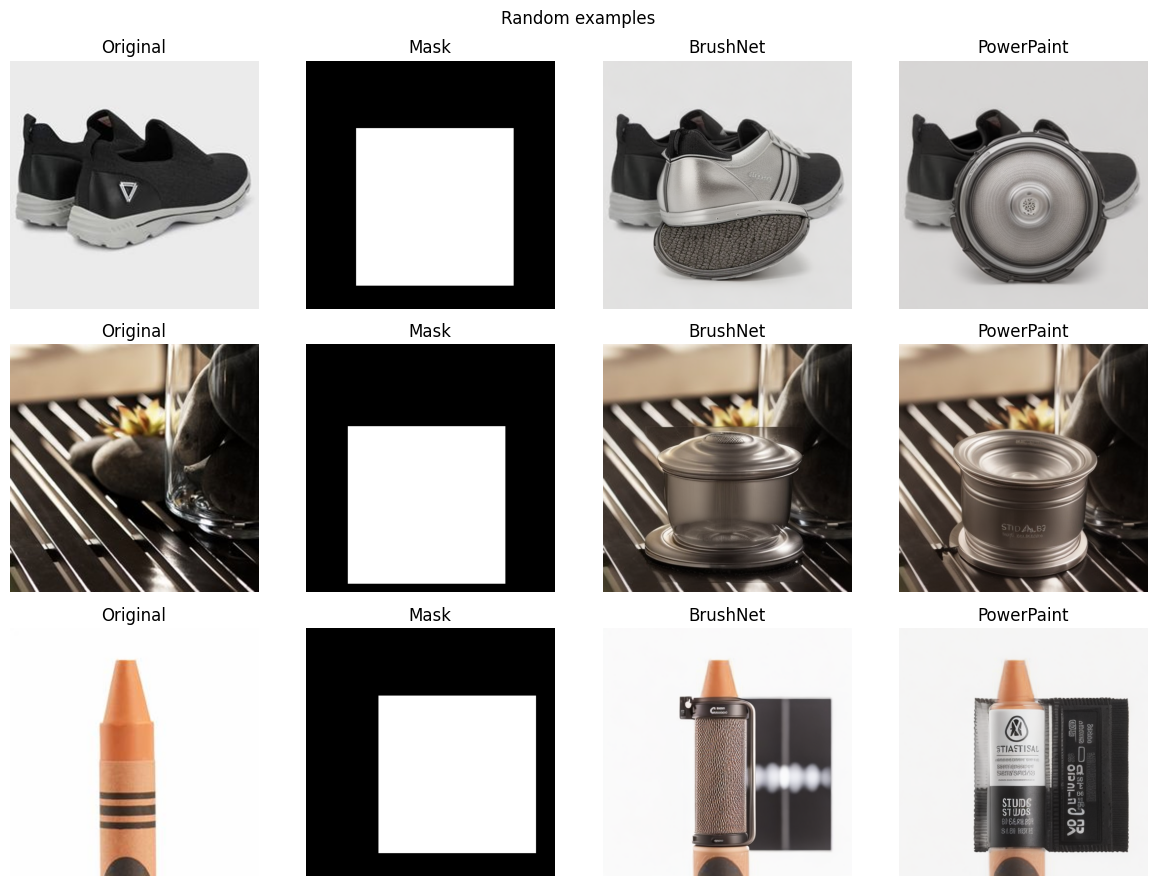

In [6]:
cases = pd.read_csv(pair / "datasets/test_cases.csv")
examples = both.merge(cases[["image_id", "mask_type", "image_path", "mask_path"]],
                      left_on=["image_id_brush", "mask_type_brush"],
                      right_on=["image_id", "mask_type"])
examples["difference"] = examples["masked_ssim_brush"] - examples["masked_ssim_power"]

def show_examples(rows, title):
    fig, axes = plt.subplots(len(rows), 4, figsize=(12, 3 * len(rows)), squeeze=False)
    for i, (_, row) in enumerate(rows.iterrows()):
        name = row["case_id"]
        paths = [
            pair / "datasets" / row["image_path"],
            pair / "datasets" / row["mask_path"],
            results / "BrushNet" / f"{name}.png",
            results / "PowerPaint" / f"{name}.png"
        ]
        for ax, path, label in zip(axes[i], paths, ["Original", "Mask", "BrushNet", "PowerPaint"]):
            # Use raw output when available
            raw = path.with_name(path.stem + "_raw.png")
            if label in ("BrushNet", "PowerPaint") and raw.exists():
                path = raw
            if path.exists():
                ax.imshow(Image.open(path), cmap="gray" if label == "Mask" else None)
            else:
                ax.text(0.5, 0.5, "Image not found", ha="center", va="center")
            ax.set_title(label)
            ax.axis("off")
        axes[i, 0].set_ylabel(name)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_examples(examples.nlargest(3, "difference"), "BrushNet higher SSIM")
show_examples(examples.nsmallest(3, "difference"), "PowerPaint higher SSIM")
show_examples(examples.sample(3, random_state=42), "Random examples")

### 5. Discussion and Recommendation

The quantitative results show that BrushNet performs better than PowerPaint in this reconstruction task. BrushNet achieved higher masked PSNR (10.558 vs 8.480), higher SSIM (0.322 vs 0.230), and lower LPIPS (0.637 vs 0.730). It was also faster, taking approximately 5 seconds per image compared with 6 seconds for PowerPaint.

The mask-size graphs show that BrushNet performs best with smaller masks, while its reconstruction quality decreases as more information is removed. PowerPaint's scores remain relatively low across all three mask sizes. The SSIM distribution also shows that BrushNet achieves more high-quality reconstruction results, although its performance varies between images.

The visual examples reveal an important limitation of both models. They sometimes generate unrelated metallic or mechanical objects instead of restoring the original product. This occurs across different product categories, suggesting that the models do not always understand what should be reconstructed from the surrounding image.

For Amazon product listings, this would be a serious issue because generated images could misrepresent the products being sold. Based on these results, BrushNet is the more suitable option for product image restoration. However, neither model should be used without checking the generated images.

This evaluation used synthetic rectangular masks and a general prompt, so the results mainly reflect reconstruction performance under these conditions. Further testing with product-specific prompts and realistic editing tasks would help determine how well the models perform in practical applications.